# Setup

In [1]:
import os
import cv2
import time
import numpy as np
import matplotlib.pyplot as plt
%matplotlib ipympl
from Util.util import load_keypoints_and_labels, get_segment_vectors, angle_between_vectors, get_gait_events, get_steps

In [43]:
recording_name = "balance1"
filename_stereo = os.path.join("data", recording_name, recording_name + "_stereo.npz")
filename_qualisys = os.path.join("data", recording_name, recording_name + "_qualisys.npz")
stereo_keypoints, stereo_labels = load_keypoints_and_labels(filename=filename_stereo)
qualisys_keypoints, qualisys_labels = load_keypoints_and_labels(filename=filename_qualisys)

filename_color_video = os.path.join("data", recording_name, recording_name + "_color.mp4")
filename_keypoints_2d = os.path.join("data", recording_name, recording_name + "_keypoints_2d.npy")
keypoints_2d = np.load(filename_keypoints_2d)

fps = 100
s_cut_1 = 700
q_cut_1 = 500

BASELINE_DURATION = 3 # seconds
q_cut_2 = q_cut_1 + len(stereo_keypoints) - s_cut_1 #TODO: this only works if the qualisys recoridng is longer than the stereo

noise_baseline_end = BASELINE_DURATION * fps

qualisys_keypoints = qualisys_keypoints[q_cut_1:q_cut_2,:,:]
stereo_keypoints = stereo_keypoints[s_cut_1:,:,:]

loaded data from: data\balance1\balance1_stereo.npz with keys: ['labels', 'keypoints']
loaded data from: data\balance1\balance1_qualisys.npz with keys: ['labels', 'keypoints']


# Add COM keypoint

In [8]:
# OVERLAY 2D COORDS ON VIDEO
cap = cv2.VideoCapture(filename_color_video)
n_frames = cap.get(cv2.CAP_PROP_FRAME_COUNT)
frame_idx = 0
while frame_idx < n_frames-1:
    ret, frame = cap.read()
    w, h, _ = frame.shape
    if not ret or frame_idx >= len(keypoints_2d):
        break

    frame_raw = cv2.rotate(frame, cv2.ROTATE_90_COUNTERCLOCKWISE)

    for x, y in keypoints_2d[frame_idx]:
        if np.isfinite(x) and np.isfinite(y):
            cv2.circle(frame_raw, (int(x), int(y)), 3, (0, 0, 255), -1)


    #COM: x% along mid_hip -> mid_shoulder
    # com_fraction = 0.15
    # mid_shoulder = keypoints_2d[frame_idx][stereo_labels.index("mid_shoulder")]
    # mid_hip = keypoints_2d[frame_idx][stereo_labels.index("mid_hip")]
    # com_x, com_y = mid_hip + com_fraction * (mid_shoulder - mid_hip)
    # if np.isfinite(com_x) and np.isfinite(com_y):
    #     cv2.circle(frame_raw, (int(com_x), int(com_y)), 6, (0, 255, 0), -1)


    cv2.putText(frame_raw, str(frame_idx), (40, 40), cv2.FONT_HERSHEY_SIMPLEX, 1, (255, 0, 0), 2)
    cv2.putText(frame_raw, 'raw', (int(w/2), 40), cv2.FONT_HERSHEY_SIMPLEX, 1, (255, 0, 0), 2)

    cv2.imshow("Raw & Filtered 2D", frame_raw)

    # Press ESC to quit
    if cv2.waitKey(1) & 0xFF == 27:
        break

    frame_idx += 1
    # time.sleep(0.075)
    time.sleep(0.03)

cap.release()
cv2.destroyAllWindows()

# parameters

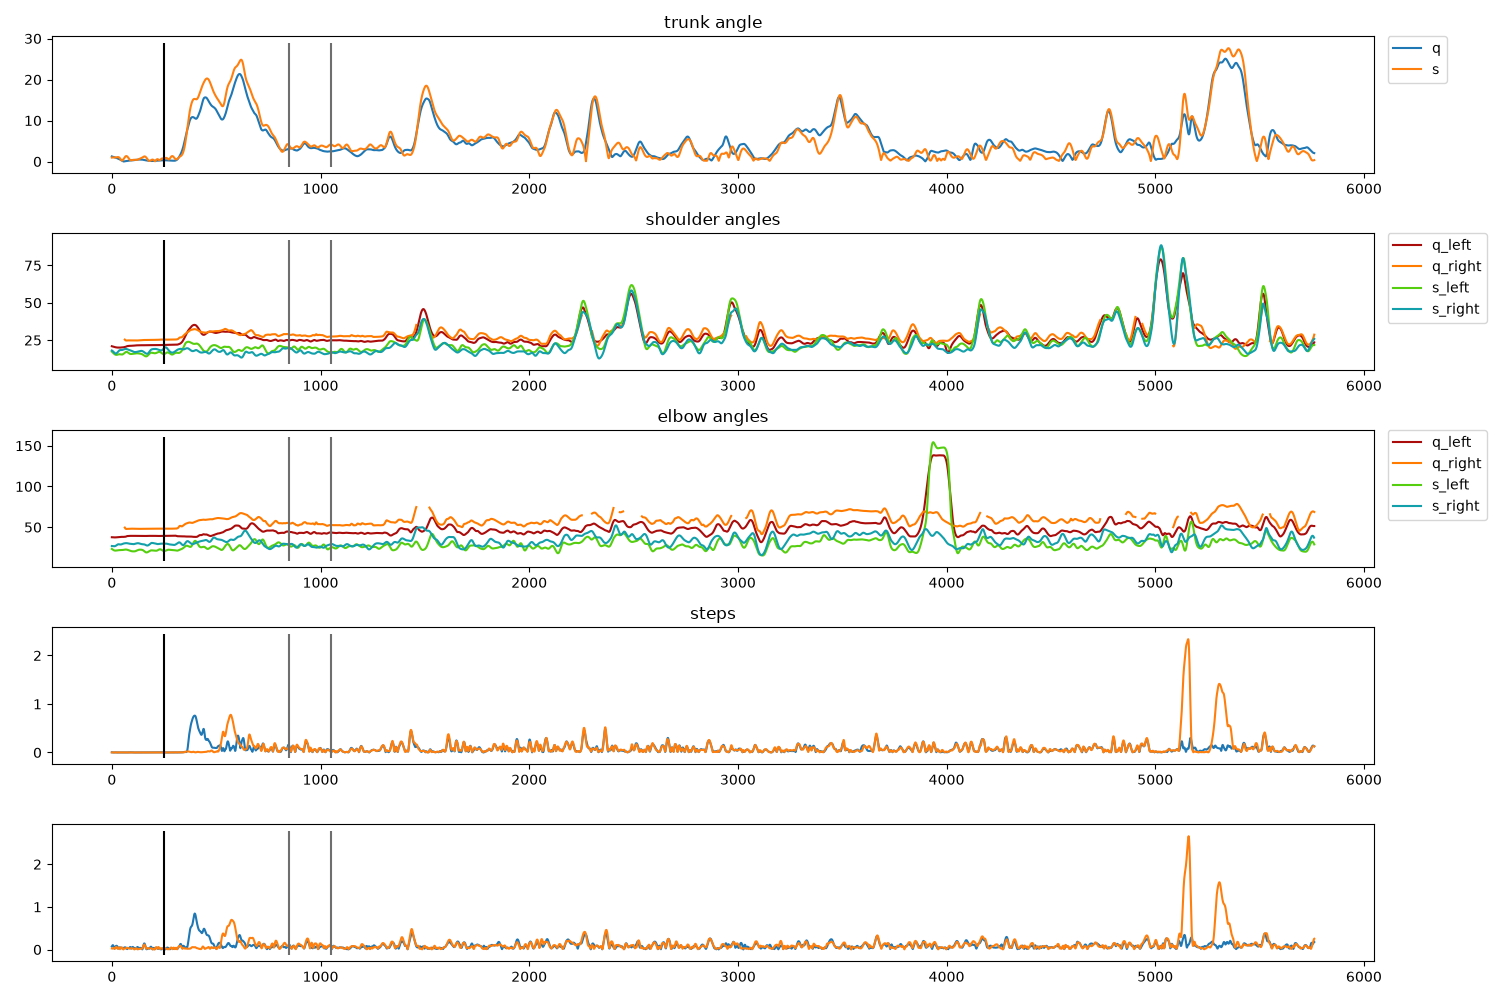

In [17]:
standing_baseline_end = 250
eyes_open_baseline_start = 850
eyes_open_baseline_end = 1050

#trunk
q_trunk = get_segment_vectors(qualisys_keypoints, qualisys_labels, "mid_shoulder", "mid_hip")
q_trunk_baseline = np.nanmean(q_trunk[:standing_baseline_end], axis=0)
q_trunk_angles = np.array([angle_between_vectors(trunk_vector, q_trunk_baseline) for trunk_vector in q_trunk])

s_trunk = get_segment_vectors(stereo_keypoints, stereo_labels, "mid_shoulder", "mid_hip")
s_trunk_baseline = np.nanmean(s_trunk[:standing_baseline_end], axis=0)
s_trunk_angles = np.array([angle_between_vectors(trunk_vector, s_trunk_baseline) for trunk_vector in s_trunk])
# arm angles

q_left_upper_arm = get_segment_vectors(qualisys_keypoints,qualisys_labels,"left_shoulder", "left_elbow")
q_left_lower_arm = get_segment_vectors(qualisys_keypoints, qualisys_labels,"left_elbow", "left_wrist")
q_right_upper_arm = get_segment_vectors(qualisys_keypoints,qualisys_labels,"right_shoulder", "right_elbow")
q_right_lower_arm = get_segment_vectors(qualisys_keypoints, qualisys_labels,"right_elbow", "right_wrist")
q_left_shoulder_angles = np.array([angle_between_vectors(upper_arm, torso) for (upper_arm, torso) in zip(q_left_upper_arm, q_trunk)])
q_left_elbow_angles = np.array([angle_between_vectors(upper_arm, lower_arm) for (upper_arm, lower_arm) in zip(q_left_upper_arm, q_left_lower_arm)])
q_right_shoulder_angles = np.array([angle_between_vectors(upper_arm, torso) for (upper_arm, torso) in zip(q_right_upper_arm, q_trunk)])
q_right_elbow_angles = np.array([angle_between_vectors(upper_arm, lower_arm) for (upper_arm, lower_arm) in zip(q_right_upper_arm, q_right_lower_arm)])


s_left_upper_arm = get_segment_vectors(stereo_keypoints,stereo_labels,"left_shoulder", "left_elbow")
s_left_lower_arm = get_segment_vectors(stereo_keypoints, stereo_labels,"left_elbow", "left_wrist")
s_right_upper_arm = get_segment_vectors(stereo_keypoints,stereo_labels,"right_shoulder", "right_elbow")
s_right_lower_arm = get_segment_vectors(stereo_keypoints, stereo_labels,"right_elbow", "right_wrist")
s_left_shoulder_angles = np.array([angle_between_vectors(upper_arm, torso) for (upper_arm, torso) in zip(s_left_upper_arm, s_trunk)])
s_left_elbow_angles = np.array([angle_between_vectors(upper_arm, lower_arm) for (upper_arm, lower_arm) in zip(s_left_upper_arm, s_left_lower_arm)])
s_right_shoulder_angles = np.array([angle_between_vectors(upper_arm, torso) for (upper_arm, torso) in zip(s_right_upper_arm, s_trunk)])
s_right_elbow_angles = np.array([angle_between_vectors(upper_arm, lower_arm) for (upper_arm, lower_arm) in zip(s_right_upper_arm, s_right_lower_arm)])

#steps

q_ankle_indices = [qualisys_labels.index("left_ankle"), qualisys_labels.index("right_ankle")]
q_baseline_ankles_pos = qualisys_keypoints[eyes_open_baseline_start :eyes_open_baseline_end, q_ankle_indices, :]  # (frames, 2, 3)
q_baseline_ankles_pos = np.nanmean(q_baseline_ankles_pos, axis=(0, 1))

q_left_ankle = qualisys_keypoints[:, qualisys_labels.index('left_ankle'),:]
q_left_ankle_speed = np.linalg.norm(np.gradient(q_left_ankle, 1/100, axis=0), axis=1)
q_right_ankle = qualisys_keypoints[:, qualisys_labels.index('right_ankle'),:]
q_right_ankle_speed = np.linalg.norm(np.gradient(q_right_ankle, 1/100, axis=0), axis=1)

q_gait_events = get_gait_events(qualisys_keypoints, qualisys_labels, 100, 0.5, 0.2, 0.2)
q_steps = get_steps(q_gait_events, qualisys_keypoints, qualisys_labels, 0.1)
for step in q_steps:
        step.set_type(qualisys_keypoints, qualisys_labels,q_baseline_ankles_pos)
        step.set_step_velocity(100)



s_ankle_indices = [stereo_labels.index("left_ankle"), stereo_labels.index("right_ankle")]
s_baseline_ankles_pos = stereo_keypoints[eyes_open_baseline_start :eyes_open_baseline_end, s_ankle_indices, :]  # (frames, 2, 3)
s_baseline_ankles_pos = np.nanmean(s_baseline_ankles_pos, axis=(0, 1))

s_left_ankle = stereo_keypoints[:, stereo_labels.index('left_ankle'),:]
s_left_ankle_speed = np.linalg.norm(np.gradient(s_left_ankle, 1/100, axis=0), axis=1)
s_right_ankle = stereo_keypoints[:, stereo_labels.index('right_ankle'),:]
s_right_ankle_speed = np.linalg.norm(np.gradient(s_right_ankle, 1/100, axis=0), axis=1)

s_gait_events = get_gait_events(stereo_keypoints, stereo_labels, 100, 0.5, 0.2, 0.2)
s_steps = get_steps(s_gait_events, stereo_keypoints, stereo_labels, 0.1)
for step in s_steps:
        step.set_type(stereo_keypoints, stereo_labels,s_baseline_ankles_pos)
        step.set_step_velocity(100)


plt.close('all')
fig, axs = plt.subplots(5,1, figsize=(15,10))


axs[0].set_title('trunk angle')
axs[0].plot(q_trunk_angles, label='q')
axs[0].plot(s_trunk_angles, label='s')
axs[0].legend(loc='upper left', bbox_to_anchor=(1.01,1), borderaxespad=0)

axs[1].set_title('shoulder angles')
axs[1].plot(q_left_shoulder_angles, color="#AA0B0B", label="q_left")
axs[1].plot(q_right_shoulder_angles,color="#FF7B00", label="q_right")
axs[1].plot(s_left_shoulder_angles, color="#55CE0F", label="s_left")
axs[1].plot(s_right_shoulder_angles,color="#12A0AA", label="s_right")
axs[1].legend(loc="upper left", bbox_to_anchor=(1.01, 1), borderaxespad=0)

axs[2].set_title('elbow angles')
axs[2].plot(q_left_elbow_angles, color="#AA0B0B", label="q_left")
axs[2].plot(q_right_elbow_angles,color="#FF7B00", label="q_right")
axs[2].plot(s_left_elbow_angles, color="#55CE0F", label="s_left")
axs[2].plot(s_right_elbow_angles,color="#12A0AA", label="s_right")
axs[2].legend(loc="upper left", bbox_to_anchor=(1.01, 1), borderaxespad=0)

axs[3].set_title('steps')
axs[3].plot(q_left_ankle_speed)
axs[3].plot(q_right_ankle_speed)
axs[4].plot(s_left_ankle_speed)
axs[4].plot(s_right_ankle_speed)


for ax in axs:
        y_min, y_max = ax.get_ylim()
        ax.vlines(standing_baseline_end, y_min, y_max, "#000000")
        ax.vlines(eyes_open_baseline_start, y_min, y_max,"#6E6E6E")
        ax.vlines(eyes_open_baseline_end, y_min, y_max,"#6E6E6E")

plt.tight_layout()

# Spectral analysis

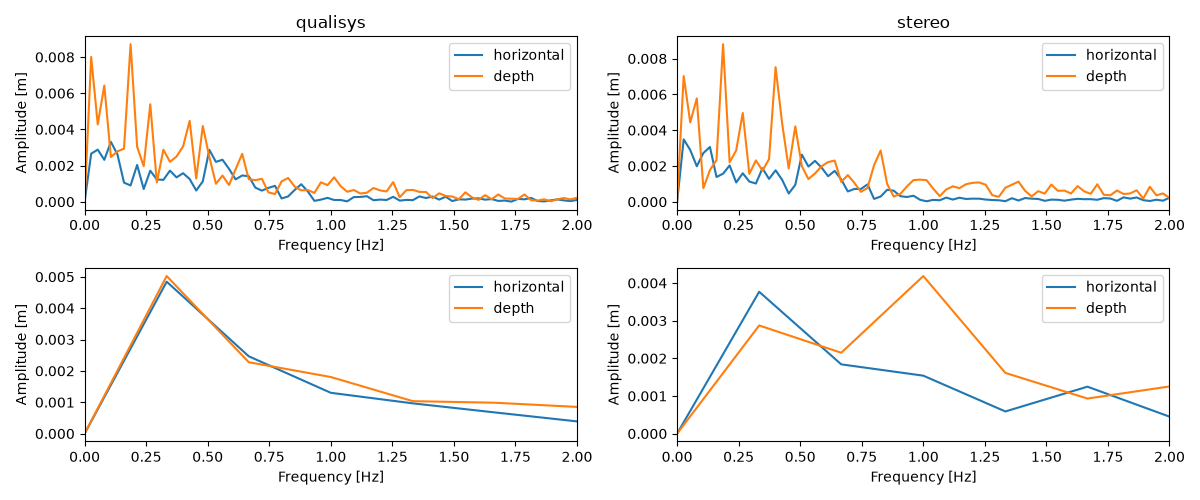

In [45]:
def get_fft_frequencies_and_amplitudes(signal, sampling_rate):
    signal_centered = signal - np.nanmean(signal, axis=0)
    frequencies = np.fft.rfftfreq(len(signal_centered), d=1/sampling_rate)
    amplitudes = 2 / len(signal_centered) * np.abs(np.fft.rfft(np.nan_to_num(signal_centered), axis=0))
    return frequencies, amplitudes

def get_spectral_parameters(frequencies, amplitudes, max_frequency):
    in_band = frequencies <= max_frequency
    frequencies = frequencies[in_band]
    power = amplitudes[in_band] ** 2
    cumulative_power_fraction = np.cumsum(power, axis=0) / np.sum(power, axis=0)

    peak_frequency = frequencies[np.argmax(amplitudes[in_band], axis=0)]
    f50 = frequencies[np.argmax(cumulative_power_fraction >= 0.5, axis=0)]
    f80 = frequencies[np.argmax(cumulative_power_fraction >= 0.8, axis=0)]
    return peak_frequency, f50, f80

# COM 
qualisys_com_pos = qualisys_keypoints[eyes_open_baseline_end:4800,qualisys_labels.index('center_of_mass'),:2]
qualisys_com_pos_baseline = qualisys_keypoints[:noise_baseline_end,qualisys_labels.index('center_of_mass'),:2]
stereo_com_pos = stereo_keypoints[eyes_open_baseline_end:4800, stereo_labels.index('center_of_mass'),:2]
stereo_com_pos_baseline = stereo_keypoints[:noise_baseline_end,stereo_labels.index('center_of_mass'),:2]


qualisys_com_frequencies, qualisys_com_amplitudes = get_fft_frequencies_and_amplitudes(qualisys_com_pos, 100)
stereo_com_frequencies, stereo_com_amplitudes = get_fft_frequencies_and_amplitudes(stereo_com_pos, 100)

q_com_baseline_freq, q_com_baseline_amp = get_fft_frequencies_and_amplitudes(qualisys_com_pos_baseline, 100)
s_com_baseline_freq, s_com_baseline_amp = get_fft_frequencies_and_amplitudes(stereo_com_pos_baseline, 100)

q_peak, q_f50, q_f80 = get_spectral_parameters(qualisys_com_frequencies, qualisys_com_amplitudes, max_frequency=5)
s_peak, s_f50, s_f80 = get_spectral_parameters(stereo_com_frequencies, stereo_com_amplitudes, max_frequency=5)

fig, axs = plt.subplots(2,2, figsize=(12,5))
axs[0,0].set_title('qualisys')
axs[0,0].plot(qualisys_com_frequencies, qualisys_com_amplitudes, label=['horizontal', 'depth'])
axs[0,0].set_xlim(0, 2)
axs[0,0].set_xlabel('Frequency [Hz]')
axs[0,0].set_ylabel('Amplitude [m]')
axs[0,0].legend()

axs[0,1].set_title('stereo')
axs[0,1].plot(stereo_com_frequencies, stereo_com_amplitudes, label=['horizontal', 'depth'])
axs[0,1].set_xlim(0, 2)
axs[0,1].set_xlabel('Frequency [Hz]')
axs[0,1].set_ylabel('Amplitude [m]')
axs[0,1].legend()

# baselines
axs[1,0].plot(q_com_baseline_freq, q_com_baseline_amp, label=['horizontal', 'depth'])
axs[1,0].set_xlim(0, 2)
axs[1,0].set_xlabel('Frequency [Hz]')
axs[1,0].set_ylabel('Amplitude [m]')
axs[1,0].legend()

axs[1,1].plot(s_com_baseline_freq, s_com_baseline_amp, label=['horizontal', 'depth'])
axs[1,1].set_xlim(0, 2)
axs[1,1].set_xlabel('Frequency [Hz]')
axs[1,1].set_ylabel('Amplitude [m]')
axs[1,1].legend()

plt.tight_layout()

C:\Users\unger\AppData\Local\Temp\ipykernel_10964\2039536250.py:5: UserWarning: nperseg=1000 is greater than signal length max(len(x), len(y)) = 300, using nperseg = 300
  frequencies, power_spectral_density = welch(signal_centered, fs=sampling_rate, nperseg=int(segment_duration * sampling_rate), axis=0)


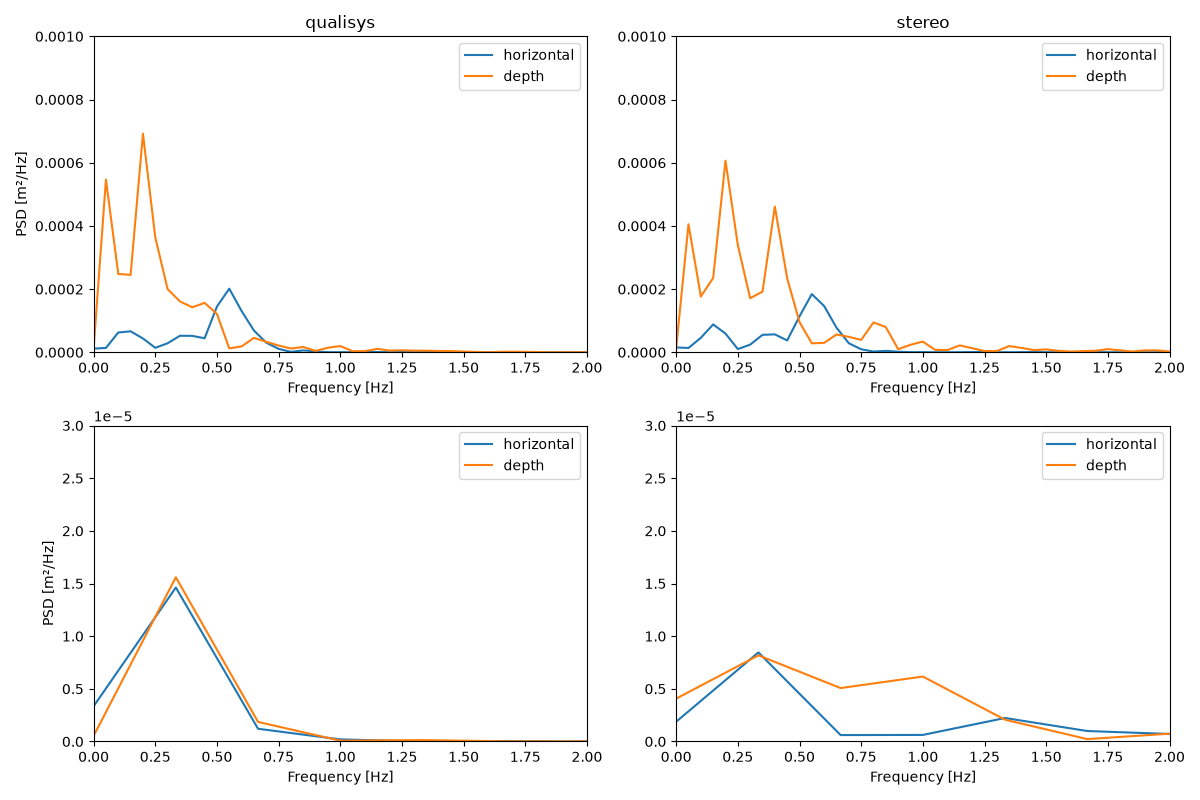

In [65]:
from scipy.signal import welch

def get_power_spectral_density(signal, sampling_rate, segment_duration):
    signal_centered = np.nan_to_num(signal - np.nanmean(signal, axis=0))
    frequencies, power_spectral_density = welch(signal_centered, fs=sampling_rate, nperseg=int(segment_duration * sampling_rate), axis=0)
    return frequencies, power_spectral_density

PSD_SEGMENT_DURATION = 20 # seconds, frequency resolution = 1 / PSD_SEGMENT_DURATION



qualisys_com_psd_frequencies, qualisys_com_psd = get_power_spectral_density(qualisys_com_pos, 100, PSD_SEGMENT_DURATION)
stereo_com_psd_frequencies, stereo_com_psd = get_power_spectral_density(stereo_com_pos, 100, PSD_SEGMENT_DURATION)

q_com_baseline_fr, q_com_baseline_psd = get_power_spectral_density(qualisys_com_pos_baseline, 100, 10)
s_com_baseline_fr, s_com_baseline_psd = get_power_spectral_density(stereo_com_pos_baseline, 100, 10)

fig, axs = plt.subplots(2,2, figsize=(12,8))
axs[0,0].set_title('qualisys')
axs[0,0].plot(qualisys_com_psd_frequencies, qualisys_com_psd, label=['horizontal', 'depth'])
axs[0,0].set_ylim([0,0.001])
axs[0,1].set_title('stereo')
axs[0,1].plot(stereo_com_psd_frequencies, stereo_com_psd, label=['horizontal', 'depth'])
axs[0,1].set_ylim([0,0.001])

axs[1,0].plot(q_com_baseline_fr, q_com_baseline_psd, label=['horizontal', 'depth'])
axs[1,0].set_ylim([0,0.00003])
axs[1,1].plot(s_com_baseline_fr, s_com_baseline_psd, label=['horizontal', 'depth'])
axs[1,1].set_ylim([0,0.00003])

for ax in axs.flat:
    ax.set_xlim(0, 2)
    ax.set_xlabel('Frequency [Hz]')
    ax.legend()
axs[0,0].set_ylabel('PSD [m²/Hz]')
axs[1,0].set_ylabel('PSD [m²/Hz]')

plt.tight_layout()